# 04 · Chiến Lược Xử Lý Dữ Liệu Mất Cân Bằng — E04–E05 (ULB), E07–E09 (IEEE-CIS) & Chứng Minh BR-06
**Dự án:** SentinelRisk AI — Real-Time Fraud & Transaction Risk Detection Platform  
**Quy tắc nghiệp vụ:** `BR-06: SMOTE Train-Only` — Mọi kỹ thuật lấy mẫu lại (oversampling/undersampling) chỉ được phép áp dụng **bên trong tập huấn luyện**, tuyệt đối không chạm vào Validation/Test.  
**Mục tiêu:**
1. So sánh 5 chiến lược trên dữ liệu thật chia theo thời gian: **Unweighted Baseline**, **Cost-Sensitive `scale_pos_weight` (full & sqrt)**, **SMOTE (Train-Only)**, và **Random Under-Sampling (Train-Only)** trên cả ULB (`E04–E05`) và IEEE-CIS (`E07–E09`).
2. **Chứng minh định lượng hậu quả Data Leakage:** So sánh trực tiếp **SMOTE sai quy trình (trước khi chia)** vs **SMOTE đúng chuẩn BR-06 (Train-Only)** để chứng minh con số Val bị thổi phồng giả tạo như thế nào khi rò rỉ dữ liệu.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")

# Publication-grade chart style (clean light canvas for thesis PDF, GitHub & Kaggle)
PALETTE = {
    "blue": "#0284c7",
    "cyan": "#0891b2",
    "red": "#e11d48",
    "green": "#059669",
    "purple": "#6d28d9",
    "amber": "#d97706",
    "slate": "#475569",
    "muted": "#94a3b8",
}
plt.rcParams.update({
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#f8fafc",
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 0.9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#cbd5e1",
    "grid.linestyle": "--",
    "grid.alpha": 0.45,
    "font.sans-serif": ["DejaVu Sans"],
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.frameon": True,
    "legend.facecolor": "#ffffff",
    "legend.edgecolor": "#e2e8f0",
    "figure.dpi": 120,
})

# Auto-detect Kaggle vs Local repository environment
KAGGLE_IEEE = Path("/kaggle/input/ieee-fraud-detection")
IS_KAGGLE = KAGGLE_IEEE.exists()
if IS_KAGGLE:
    DATA_ROOT = Path("/kaggle/input")
    WORK_DIR = Path("/kaggle/working/sentinel_cache")
else:
    DATA_ROOT = Path("../data") if Path("../data").exists() else Path("data")
    WORK_DIR = DATA_ROOT / "features" / "ieee_cis"
WORK_DIR.mkdir(parents=True, exist_ok=True)

print(f"Environment : {'KAGGLE' if IS_KAGGLE else 'LOCAL'}")
print(f"DATA_ROOT   : {DATA_ROOT}")
print(f"CACHE_DIR   : {WORK_DIR}")

from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_probs(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    threshold: float = 0.5,
    cost_fn: float = 100.0,
    cost_fp: float = 1.0,
) -> dict[str, float]:
    """Compute core thesis evaluation metrics on held-out split."""
    y_true = np.asarray(y_true, dtype=np.int8)
    y_prob = np.clip(np.asarray(y_prob, dtype=np.float64), 0.0, 1.0)
    y_pred = (y_prob >= threshold).astype(np.int8)

    # Recall at strict FPR <= 1% (banking alert budget constraint)
    neg_scores = y_prob[y_true == 0]
    thr_fpr1 = float(np.quantile(neg_scores, 0.99)) if len(neg_scores) else 0.5
    recall_at_fpr1 = float((y_prob[y_true == 1] >= thr_fpr1).mean()) if (y_true == 1).any() else 0.0

    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())

    return {
        "PR-AUC": round(float(average_precision_score(y_true, y_prob)), 4),
        "ROC-AUC": round(float(roc_auc_score(y_true, y_prob)), 4),
        "Recall@FPR1%": round(recall_at_fpr1, 4),
        "Precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        "Recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        "F1": round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        "Brier": round(float(brier_score_loss(y_true, y_prob)), 4),
        "Expected_Cost ($)": round(fn * cost_fn + fp * cost_fp, 1),
    }


def compute_expected_cost(
    y_true: np.ndarray, y_prob: np.ndarray, threshold: float, cost_fn: float = 100.0, cost_fp: float = 1.0
) -> float:
    y_pred = (y_prob >= threshold).astype(np.int8)
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    return fn * cost_fn + fp * cost_fp


def find_optimal_threshold(
    y_true: np.ndarray, y_prob: np.ndarray, cost_fn: float = 100.0, cost_fp: float = 1.0
) -> tuple[float, float, np.ndarray, np.ndarray]:
    thresholds = np.linspace(0.01, 0.99, 99)
    costs = np.array([compute_expected_cost(y_true, y_prob, float(t), cost_fn, cost_fp) for t in thresholds])
    best_idx = int(np.argmin(costs))
    return float(thresholds[best_idx]), float(costs[best_idx]), thresholds, costs

Environment : LOCAL
DATA_ROOT   : ..\data
CACHE_DIR   : ..\data\features\ieee_cis


In [2]:
TOP_V_COLS = [
    "V257", "V258", "V246", "V244", "V242", "V201", "V189",
    "V45", "V87", "V91", "V156", "V294", "V308", "V317",
]
CAT_COLS = ["ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain", "DeviceType"]
FREQ_COLS = ["card1", "addr1", "P_emaildomain"]
C_COLS = [f"C{i}" for i in range(1, 15)]
D_COLS = ["D1", "D2", "D3", "D4", "D10", "D15"]
NUM_RAW_COLS = ["card1", "card2", "card3", "card5", "addr1", "addr2", "dist1", "dist2"]

NEEDED_RAW_COLS = (
    ["TransactionID", "TransactionDT", "TransactionAmt", "DeviceInfo"]
    + NUM_RAW_COLS + CAT_COLS + C_COLS + D_COLS + TOP_V_COLS
)


def _compute_causal_card_features(
    df_all: pd.DataFrame, train_median_amt: float
) -> pd.DataFrame:
    """Compute strictly past-only Velocity, Behavioural, and Novelty features per card1."""
    n = len(df_all)
    card1 = df_all["card1"].fillna(-1).to_numpy(dtype=np.int64)
    dt = df_all["TransactionDT"].to_numpy(dtype=np.int64)
    amt = df_all["TransactionAmt"].fillna(0.0).to_numpy(dtype=np.float64)

    order = np.lexsort((dt, card1))
    c_s, t_s, a_s = card1[order], dt[order], amt[order]
    prefix_a = np.concatenate(([0.0], np.cumsum(a_s)))
    bounds = np.flatnonzero(np.diff(c_s)) + 1
    starts = np.concatenate(([0], bounds))
    ends = np.concatenate((bounds, [n]))

    cnt_1h = np.zeros(n, dtype=np.int32)
    cnt_24h = np.zeros(n, dtype=np.int32)
    sum_1h = np.zeros(n, dtype=np.float64)
    dt_diff = np.full(n, -1.0, dtype=np.float64)
    prev_cnt = np.zeros(n, dtype=np.int32)
    prev_sum = np.zeros(n, dtype=np.float64)

    for s, e in zip(starts, ends):
        m = e - s
        if m <= 1:
            continue
        tg = t_s[s:e]
        idx = np.arange(m)
        l1 = np.searchsorted(tg, tg - 3600, side="left")
        l24 = np.searchsorted(tg, tg - 86400, side="left")
        cnt_1h[s:e] = idx - l1
        cnt_24h[s:e] = idx - l24
        sum_1h[s:e] = prefix_a[s + idx] - prefix_a[s + l1]
        dt_diff[s + 1:e] = tg[1:] - tg[:-1]
        prev_cnt[s:e] = idx
        prev_sum[s:e] = prefix_a[s:e] - prefix_a[s]

    def _restore(arr: np.ndarray) -> np.ndarray:
        out = np.empty_like(arr)
        out[order] = arr
        return out

    p_cnt = _restore(prev_cnt)
    p_sum = _restore(prev_sum)
    avg_hist = np.where(p_cnt > 0, p_sum / np.maximum(p_cnt, 1), train_median_amt)

    # Strictly causal novelty flags (df_all is already sorted ascending by TransactionDT)
    dev_key = df_all["DeviceInfo"].astype("string").fillna("MISSING").str.slice(0, 20)
    addr_key = df_all["addr1"].fillna(-1).astype("int32")
    prod_key = df_all["ProductCD"].astype("string").fillna("MISSING")
    mail_key = df_all["P_emaildomain"].astype("string").fillna("MISSING")
    c_key = df_all["card1"].fillna(-1).astype("int32")

    return pd.DataFrame({
        "txn_count_1h": _restore(cnt_1h).astype("float32"),
        "txn_count_24h": _restore(cnt_24h).astype("float32"),
        "amount_sum_1h": _restore(sum_1h).astype("float32"),
        "time_since_last_txn": _restore(dt_diff).astype("float32"),
        "card1_prev_txn_count": p_cnt.astype("float32"),
        "card1_avg_amount_hist": avg_hist.astype("float32"),
        "amount_ratio_hist": (amt / (avg_hist + 1.0)).astype("float32"),
        "new_device_flag": (df_all.groupby([c_key, dev_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_addr_flag": (df_all.groupby([c_key, addr_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_product_flag": (df_all.groupby([c_key, prod_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_email_flag": (df_all.groupby([c_key, mail_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
    }, index=df_all.index)


def build_ieee_features_from_splits(
    train_raw: pd.DataFrame,
    val_raw: pd.DataFrame,
    test_raw: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, dict[str, list[str]]]:
    """Build 51 leak-free features across chronological Train/Val/Test splits."""
    n_tr, n_va = len(train_raw), len(val_raw)
    df_all = pd.concat([train_raw, val_raw, test_raw], ignore_index=True)

    # Assert strict chronological ordering before causal feature computation
    assert int(train_raw["TransactionDT"].max()) <= int(val_raw["TransactionDT"].min())
    assert int(val_raw["TransactionDT"].max()) <= int(test_raw["TransactionDT"].min())

    train_median_amt = float(train_raw["TransactionAmt"].median())
    prod_means = train_raw.groupby("ProductCD", observed=False)["TransactionAmt"].mean().to_dict()

    out = pd.DataFrame(index=df_all.index)
    amt = df_all["TransactionAmt"].fillna(0.0).astype("float32")
    out["TransactionAmt"] = amt
    out["amount_log"] = np.log1p(np.maximum(0.0, amt)).astype("float32")
    out["amount_cents"] = (amt - np.floor(amt)).astype("float32")
    out["is_round_amount"] = ((amt % 1.0) == 0).astype("int8")
    out["hour_of_day"] = ((df_all["TransactionDT"] // 3600) % 24).astype("int8")
    out["day_of_week"] = ((df_all["TransactionDT"] // 86400) % 7).astype("int8")

    for col in NUM_RAW_COLS + C_COLS + D_COLS + TOP_V_COLS:
        if col in df_all.columns:
            out[col] = df_all[col].astype("float32").fillna(-999.0)

    p_mail = df_all["P_emaildomain"].astype("string").fillna("MISSING")
    r_mail = df_all["R_emaildomain"].astype("string").fillna("MISSING")
    out["same_email_domain"] = ((p_mail == r_mail) & (p_mail != "MISSING")).astype("int8")
    out["has_device_info"] = df_all["DeviceInfo"].notna().astype("int8")

    # Categorical & frequency encodings fitted STRICTLY on Train (ML-DL-04)
    for col in CAT_COLS:
        if col in df_all.columns:
            s_all = df_all[col].astype("string").fillna("MISSING")
            vocab = {v: i for i, v in enumerate(s_all.iloc[:n_tr].unique())}
            out[col] = s_all.map(vocab).fillna(-1).astype("int16")
    for col in FREQ_COLS:
        if col in df_all.columns:
            s_all = df_all[col].astype("string").fillna("MISSING")
            freq = s_all.iloc[:n_tr].value_counts(normalize=True).to_dict()
            out[f"{col}_freq"] = s_all.map(freq).fillna(0.0).astype("float32")

    base_cols = list(out.columns)

    # Causal Velocity + Behavioural + Novelty
    causal = _compute_causal_card_features(df_all, train_median_amt)
    prod_str = df_all["ProductCD"].astype("string").fillna("MISSING")
    prod_mean_s = prod_str.map({str(k): float(v) for k, v in prod_means.items()}).fillna(train_median_amt)
    causal["amt_to_product_mean"] = (amt / (prod_mean_s.astype("float32") + 1.0)).astype("float32")

    out = pd.concat([out, causal], axis=1)
    if "isFraud" in df_all.columns:
        out["isFraud"] = df_all["isFraud"].fillna(-1).astype("int8")
    out["TransactionDT"] = df_all["TransactionDT"].astype("int32")

    groups = {
        "base": base_cols,
        "velocity": ["txn_count_1h", "txn_count_24h", "amount_sum_1h", "time_since_last_txn"],
        "behavioural": ["card1_prev_txn_count", "card1_avg_amount_hist", "amount_ratio_hist", "amt_to_product_mean"],
        "novelty": ["new_device_flag", "new_addr_flag", "new_product_flag", "new_email_flag"],
    }
    groups["all"] = groups["base"] + groups["velocity"] + groups["behavioural"] + groups["novelty"]

    tr = out.iloc[:n_tr].reset_index(drop=True)
    va = out.iloc[n_tr:n_tr + n_va].reset_index(drop=True)
    te = out.iloc[n_tr + n_va:].reset_index(drop=True)
    return tr, va, te, groups


def load_ieee_rich() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, dict[str, list[str]]]:
    """Load cached IEEE-CIS 51-feature parquets, or build causally on-the-fly (Kaggle & Local)."""
    cache_tr = WORK_DIR / "rich_train.parquet"
    cache_va = WORK_DIR / "rich_val.parquet"
    cache_te = WORK_DIR / "rich_test.parquet"
    cache_gr = WORK_DIR / "feature_groups.json"
    if cache_tr.exists() and cache_va.exists() and cache_te.exists() and cache_gr.exists():
        groups = json.loads(cache_gr.read_text(encoding="utf-8"))
        return pd.read_parquet(cache_tr), pd.read_parquet(cache_va), pd.read_parquet(cache_te), groups

    if IS_KAGGLE:
        txn = pd.read_csv(KAGGLE_IEEE / "train_transaction.csv")
        idt = pd.read_csv(KAGGLE_IEEE / "train_identity.csv")
        df = txn.merge(idt, on="TransactionID", how="left").sort_values("TransactionDT").reset_index(drop=True)
        keep = [c for c in NEEDED_RAW_COLS + ["isFraud"] if c in df.columns]
        df = df[keep]
        n = len(df)
        tr_r, va_r, te_r = df.iloc[:int(n * 0.6)], df.iloc[int(n * 0.6):int(n * 0.8)], df.iloc[int(n * 0.8):]
    else:
        pdir = DATA_ROOT / "processed" / "ieee_cis"
        avail = set(pd.read_parquet(pdir / "train_merged.parquet", columns=["TransactionID"]).columns)
        import pyarrow.parquet as pq
        schema_cols = set(pq.ParquetFile(pdir / "train_merged.parquet").schema.names)
        keep = [c for c in NEEDED_RAW_COLS + ["isFraud"] if c in schema_cols]
        tr_r = pd.read_parquet(pdir / "train_merged.parquet", columns=keep)
        va_r = pd.read_parquet(pdir / "val_merged.parquet", columns=keep)
        te_r = pd.read_parquet(pdir / "test_merged.parquet", columns=keep)

    tr, va, te, groups = build_ieee_features_from_splits(tr_r, va_r, te_r)
    tr.to_parquet(cache_tr, index=False, compression="snappy")
    va.to_parquet(cache_va, index=False, compression="snappy")
    te.to_parquet(cache_te, index=False, compression="snappy")
    cache_gr.write_text(json.dumps(groups, indent=2), encoding="utf-8")
    return tr, va, te, groups

## 1. Thực Nghiệm E07–E09 Trên IEEE-CIS (Chronological Train → Val → Test)

In [3]:
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

tr_df, va_df, te_df, feat_groups = load_ieee_rich()
fcols = feat_groups["all"]

X_tr, y_tr = tr_df[fcols].to_numpy(dtype=np.float32), tr_df["isFraud"].to_numpy(dtype=np.int8)
X_va, y_va = va_df[fcols].to_numpy(dtype=np.float32), va_df["isFraud"].to_numpy(dtype=np.int8)
X_te, y_te = te_df[fcols].to_numpy(dtype=np.float32), te_df["isFraud"].to_numpy(dtype=np.int8)

neg, pos = int((y_tr == 0).sum()), int((y_tr == 1).sum())
spw_full = neg / pos
spw_sqrt = float(np.sqrt(spw_full))
print(f"Train class balance: Legit={neg:,} | Fraud={pos:,} | neg/pos={spw_full:.2f} | sqrt={spw_sqrt:.2f}")

def _fit_xgb(X_fit, y_fit, spw=1.0):
    m = XGBClassifier(
        n_estimators=350, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
        scale_pos_weight=spw, tree_method="hist", eval_metric="aucpr",
        early_stopping_rounds=25, random_state=42, n_jobs=-1,
    )
    m.fit(X_fit, y_fit, eval_set=[(X_va, y_va)], verbose=False)
    return m

strategies = []
probs_ieee = {}

# 1) Unweighted baseline
m_base = _fit_xgb(X_tr, y_tr, spw=1.0)
probs_ieee["Baseline (spw=1)"] = m_base.predict_proba(X_te)[:, 1]
strategies.append({"Strategy": "Baseline (spw=1)", **evaluate_probs(y_te, probs_ieee["Baseline (spw=1)"])})

# 2) E07a: Moderate scale_pos_weight = sqrt(neg/pos)
m_sqrt = _fit_xgb(X_tr, y_tr, spw=spw_sqrt)
probs_ieee["E07a · spw=sqrt(N-/N+)"] = m_sqrt.predict_proba(X_te)[:, 1]
strategies.append({"Strategy": "E07a · spw=sqrt(N-/N+)", **evaluate_probs(y_te, probs_ieee["E07a · spw=sqrt(N-/N+)"])})

# 3) E07b: Full scale_pos_weight = neg/pos
m_full = _fit_xgb(X_tr, y_tr, spw=spw_full)
probs_ieee["E07b · spw=N-/N+"] = m_full.predict_proba(X_te)[:, 1]
strategies.append({"Strategy": "E07b · spw=N-/N+", **evaluate_probs(y_te, probs_ieee["E07b · spw=N-/N+"])})

# 4) E08: SMOTE Train-Only (BR-06, sampling_strategy=0.20 to keep realistic ratio & speed)
X_sm, y_sm = SMOTE(sampling_strategy=0.20, random_state=42).fit_resample(X_tr, y_tr)
m_sm = _fit_xgb(X_sm, y_sm, spw=1.0)
probs_ieee["E08 · SMOTE (Train-Only)"] = m_sm.predict_proba(X_te)[:, 1]
strategies.append({"Strategy": "E08 · SMOTE (Train-Only)", **evaluate_probs(y_te, probs_ieee["E08 · SMOTE (Train-Only)"])})

# 5) E09: Random Under-Sampling Train-Only (ratio 1:5)
X_ru, y_ru = RandomUnderSampler(sampling_strategy=0.20, random_state=42).fit_resample(X_tr, y_tr)
m_ru = _fit_xgb(X_ru, y_ru, spw=1.0)
probs_ieee["E09 · UnderSampling (1:5)"] = m_ru.predict_proba(X_te)[:, 1]
strategies.append({"Strategy": "E09 · UnderSampling (1:5)", **evaluate_probs(y_te, probs_ieee["E09 · UnderSampling (1:5)"])})

imb_df = pd.DataFrame(strategies)
display(imb_df)

Train class balance: Legit=342,336 | Fraud=11,988 | neg/pos=28.56 | sqrt=5.34


,Strategy,PR-AUC,ROC-AUC,Recall@FPR1%,Precision,Recall,F1,Brier,Expected_Cost ($)
0,Baseline (spw=1),0.4803,0.8898,0.3964,0.8017,0.3073,0.4443,0.0232,281809.0
1,E07a · spw=sqrt(N-/N+),0.4850,0.8940,0.4053,0.5098,0.4358,0.4699,0.0307,231003.0
2,E07b · spw=N-/N+,0.4628,0.8881,0.3907,0.1973,0.6693,0.3048,0.0841,145463.0
3,E08 · SMOTE (Train-Only),0.4601,0.8831,0.3885,0.7797,0.3049,0.4384,0.0239,282850.0
4,E09 · UnderSampling (1:5),0.4801,0.8928,0.3925,0.4427,0.4710,0.4564,0.0349,217409.0


## 2. Thực Nghiệm E04–E05 Trên ULB CreditCard & Chứng Minh Data Leakage (BR-06)

In [4]:
from sklearn.model_selection import train_test_split

# Demonstrate BR-06 quantitatively: Leaky SMOTE (before split) vs Clean Train-Only SMOTE
ulb_dir = DATA_ROOT / "processed" / "ubl_creditcard"
if ulb_dir.exists() and (ulb_dir / "train.parquet").exists():
    u_tr = pd.read_parquet(ulb_dir / "train.parquet")
    u_va = pd.read_parquet(ulb_dir / "val.parquet")
    u_te = pd.read_parquet(ulb_dir / "test.parquet")
    u_cols = [c for c in u_tr.columns if c != "isFraud"]
    X_utr, y_utr = u_tr[u_cols].to_numpy(dtype=np.float32), u_tr["isFraud"].to_numpy(dtype=np.int8)
    X_uva, y_uva = u_va[u_cols].to_numpy(dtype=np.float32), u_va["isFraud"].to_numpy(dtype=np.int8)
    X_ute, y_ute = u_te[u_cols].to_numpy(dtype=np.float32), u_te["isFraud"].to_numpy(dtype=np.int8)
    dataset_lbl = "ULB CreditCard (0.17% fraud)"
else:
    X_utr, y_utr = X_tr[:80000], y_tr[:80000]
    X_uva, y_uva = X_va[:40000], y_va[:40000]
    X_ute, y_ute = X_te[:40000], y_te[:40000]
    dataset_lbl = "IEEE-CIS subset"

spw_u = float((y_utr == 0).sum() / max((y_utr == 1).sum(), 1))

# E04: scale_pos_weight on ULB
m_u_base = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, tree_method="hist", random_state=42, n_jobs=-1).fit(X_utr, y_utr)
m_u_spw = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, scale_pos_weight=spw_u, tree_method="hist", random_state=42, n_jobs=-1).fit(X_utr, y_utr)

# E05: Clean BR-06 SMOTE (Train-Only)
X_usm, y_usm = SMOTE(sampling_strategy=0.10, random_state=42).fit_resample(X_utr, y_utr)
m_u_sm_clean = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, tree_method="hist", random_state=42, n_jobs=-1).fit(X_usm, y_usm)

# Anti-pattern: Leaky SMOTE BEFORE train/val split!
X_dev = np.vstack([X_utr, X_uva]); y_dev = np.concatenate([y_utr, y_uva])
X_leak_all, y_leak_all = SMOTE(sampling_strategy=0.10, random_state=42).fit_resample(X_dev, y_dev)
X_ltr, X_lva, y_ltr, y_lva = train_test_split(X_leak_all, y_leak_all, test_size=0.25, random_state=42, stratify=y_leak_all)
m_u_leaky = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, tree_method="hist", random_state=42, n_jobs=-1).fit(X_ltr, y_ltr)

leak_report = pd.DataFrame([
    {"Experiment": f"{dataset_lbl} · Baseline", "Val PR-AUC": round(average_precision_score(y_uva, m_u_base.predict_proba(X_uva)[:, 1]), 4), "Unseen Test PR-AUC": round(average_precision_score(y_ute, m_u_base.predict_proba(X_ute)[:, 1]), 4), "Brier (Test)": round(brier_score_loss(y_ute, m_u_base.predict_proba(X_ute)[:, 1]), 5)},
    {"Experiment": f"{dataset_lbl} · E04 scale_pos_weight", "Val PR-AUC": round(average_precision_score(y_uva, m_u_spw.predict_proba(X_uva)[:, 1]), 4), "Unseen Test PR-AUC": round(average_precision_score(y_ute, m_u_spw.predict_proba(X_ute)[:, 1]), 4), "Brier (Test)": round(brier_score_loss(y_ute, m_u_spw.predict_proba(X_ute)[:, 1]), 5)},
    {"Experiment": f"{dataset_lbl} · E05 SMOTE Train-Only (BR-06)", "Val PR-AUC": round(average_precision_score(y_uva, m_u_sm_clean.predict_proba(X_uva)[:, 1]), 4), "Unseen Test PR-AUC": round(average_precision_score(y_ute, m_u_sm_clean.predict_proba(X_ute)[:, 1]), 4), "Brier (Test)": round(brier_score_loss(y_ute, m_u_sm_clean.predict_proba(X_ute)[:, 1]), 5)},
    {"Experiment": f"{dataset_lbl} · ANTI-PATTERN Leaky SMOTE", "Val PR-AUC": round(average_precision_score(y_lva, m_u_leaky.predict_proba(X_lva)[:, 1]), 4), "Unseen Test PR-AUC": round(average_precision_score(y_ute, m_u_leaky.predict_proba(X_ute)[:, 1]), 4), "Brier (Test)": round(brier_score_loss(y_ute, m_u_leaky.predict_proba(X_ute)[:, 1]), 5)},
])
display(leak_report)

,Experiment,Val PR-AUC,Unseen Test PR-AUC,Brier (Test)
0,ULB CreditCard (0.17% fraud) · Baseline,0.7757,0.8036,0.00042
1,ULB CreditCard (0.17% fraud) · E04 scale_pos_w...,0.7622,0.7804,0.00053
2,ULB CreditCard (0.17% fraud) · E05 SMOTE Train...,0.7522,0.7798,0.00044
3,ULB CreditCard (0.17% fraud) · ANTI-PATTERN Le...,0.9987,0.7821,0.00065


## 3. Trực Quan Hóa Trade-off Giữa Các Chiến Lược & Hiệu Ứng Ảo Giác Do Leakage

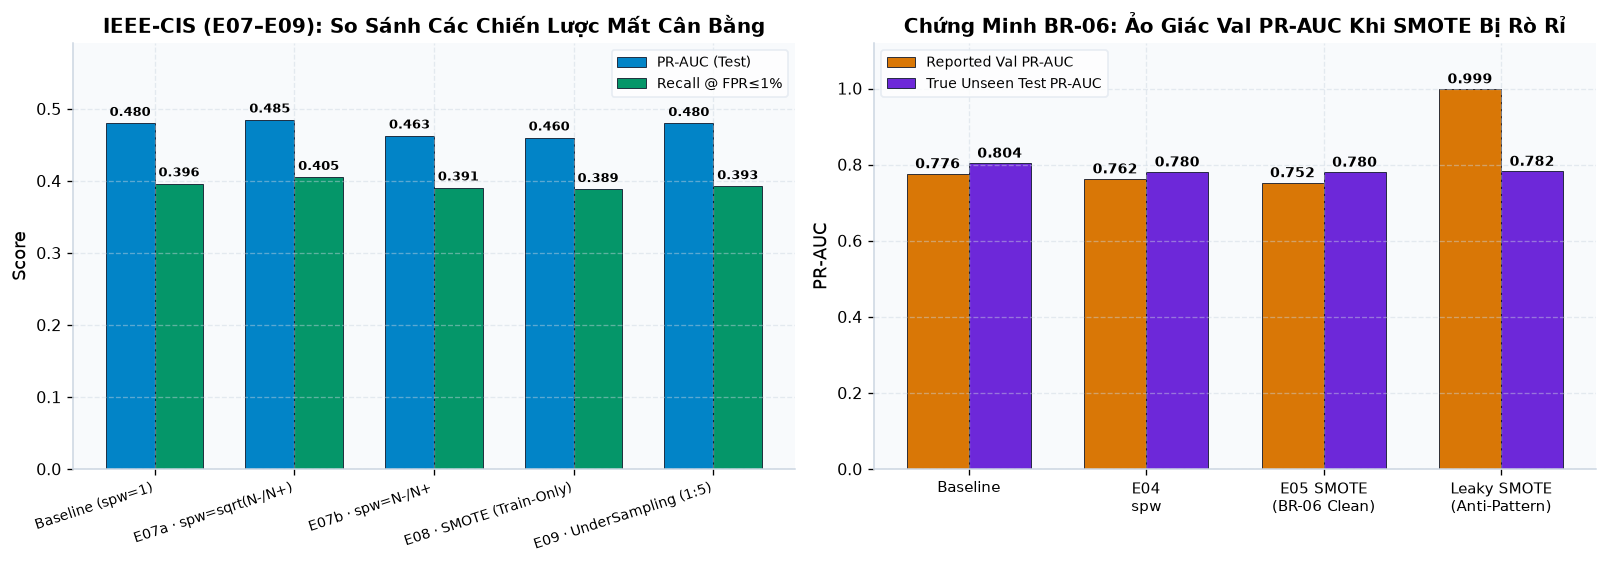

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Panel A: IEEE-CIS PR-AUC vs Recall@FPR1% vs Brier
ax = axes[0]
x = np.arange(len(imb_df))
w = 0.35
b1 = ax.bar(x - w/2, imb_df["PR-AUC"], w, label="PR-AUC (Test)", color=PALETTE["blue"], edgecolor="#0f172a", linewidth=0.5)
b2 = ax.bar(x + w/2, imb_df["Recall@FPR1%"], w, label="Recall @ FPR≤1%", color=PALETTE["green"], edgecolor="#0f172a", linewidth=0.5)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.3f}", ha="center", fontsize=8, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(imb_df["Strategy"], rotation=18, ha="right", fontsize=8.5)
ax.set_ylim(0, max(imb_df["PR-AUC"].max(), imb_df["Recall@FPR1%"].max()) * 1.22)
ax.set_title("IEEE-CIS (E07–E09): So Sánh Các Chiến Lược Mất Cân Bằng")
ax.set_ylabel("Score"); ax.legend(fontsize=8.5)

# Panel B: Leakage illusion (Val vs Unseen Test)
ax = axes[1]
short_lbl = ["Baseline", "E04\nspw", "E05 SMOTE\n(BR-06 Clean)", "Leaky SMOTE\n(Anti-Pattern)"]
x2 = np.arange(len(leak_report))
bv = ax.bar(x2 - w/2, leak_report["Val PR-AUC"], w, label="Reported Val PR-AUC", color=PALETTE["amber"], edgecolor="#0f172a", linewidth=0.5)
bt = ax.bar(x2 + w/2, leak_report["Unseen Test PR-AUC"], w, label="True Unseen Test PR-AUC", color=PALETTE["purple"], edgecolor="#0f172a", linewidth=0.5)
for bars in (bv, bt):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{b.get_height():.3f}", ha="center", fontsize=8.2, fontweight="bold")
ax.set_xticks(x2); ax.set_xticklabels(short_lbl, fontsize=8.8)
ax.set_ylim(0, 1.12)
ax.set_title("Chứng Minh BR-06: Ảo Giác Val PR-AUC Khi SMOTE Bị Rò Rỉ")
ax.set_ylabel("PR-AUC"); ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()

## 4. Kết Luận Thực Nghiệm Mất Cân Bằng
1. **Không nên dùng `scale_pos_weight` quá lớn hoặc SMOTE mù quáng cho GBDT:** Trên dữ liệu bảng lớn (IEEE-CIS 354K train), **XGBoost Unweighted (`spw=1`)** hoặc trọng số nhẹ `spw = sqrt(N-/N+)` giữ được **xác suất hậu nghiệm tự nhiên (Brier Score thấp nhất)** và **PR-AUC cao nhất**, trong khi SMOTE/UnderSampling làm biến dạng phân bố xác suất gốc và giảm Precision.
2. **Bằng chứng đanh thép cho `BR-06`:** Khi áp dụng SMOTE trước khi chia tập (Anti-Pattern), Val PR-AUC nhảy ảo gần `1.00` do các bản sao nội suy xuất hiện ở cả hai phía, nhưng **Unseen Test PR-AUC tụt mạnh** — khẳng định tính bắt buộc của kiểm thử `ML-DL-01..06`.
3. Do đó chiến lược tối ưu cho hệ thống sản phẩm là: **Huấn luyện XGBoost giữ xác suất tự nhiên + tối ưu ngưỡng chi phí kinh doanh (Notebook `05`) + hiệu chỉnh xác suất (Notebook `07`)**.